In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Libraries loaded successfully!")


Libraries loaded successfully!


In [2]:
import os
import pandas as pd

if os.path.exists("data/ml-1m/ratings.dat"):
    data_path = "data/ml-1m"
elif os.path.exists("data/ratings.dat"):
    data_path = "data"
else:
    raise FileNotFoundError(
        "Could not find ratings.dat. Check your MovieLens files."
    )

print("Dataset path:", data_path)


# Load ratings
ratings = pd.read_csv(
    os.path.join(data_path, "ratings.dat"),
    sep="::",
    engine="python",
    names=["userId", "movieId", "rating", "timestamp"]
)

# Load movies
movies = pd.read_csv(
    os.path.join(data_path, "movies.dat"),
    sep="::",
    engine="python",
    encoding="latin-1",
    names=["movieId", "title", "genres"]
)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

Dataset path: data/ml-1m
Ratings shape: (1000209, 4)
Movies shape: (3883, 3)


In [3]:
print("RATINGS")
display(ratings.head())

print("\nMOVIES")
display(movies.head())

RATINGS


,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291



MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
print("Number of users:", ratings["userId"].nunique())
print("Number of movies:", ratings["movieId"].nunique())
print("Rating range:", ratings["rating"].min(), "to", ratings["rating"].max())

Number of users: 6040
Number of movies: 3706
Rating range: 1 to 5


In [5]:
data = ratings.merge(
    movies,
    on="movieId",
    how="left"
)

display(data.head())

,userId,movieId,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [6]:
#converting timestamp to date time format
data["datetime"] = pd.to_datetime(
    data["timestamp"],
    unit="s"
)

display(
    data[
        ["userId", "movieId", "rating", "datetime", "title"]
    ].head(10)
)

,userId,movieId,rating,datetime,title
0,1,1193,5,2000-12-31 22:12:40,One Flew Over the Cuckoo's Nest (1975)
1,1,661,3,2000-12-31 22:35:09,James and the Giant Peach (1996)
2,1,914,3,2000-12-31 22:32:48,My Fair Lady (1964)
3,1,3408,4,2000-12-31 22:04:35,Erin Brockovich (2000)
4,1,2355,5,2001-01-06 23:38:11,"Bug's Life, A (1998)"
5,1,1197,3,2000-12-31 22:37:48,"Princess Bride, The (1987)"
6,1,1287,5,2000-12-31 22:33:59,Ben-Hur (1959)
7,1,2804,5,2000-12-31 22:11:59,"Christmas Story, A (1983)"
8,1,594,4,2000-12-31 22:37:48,Snow White and the Seven Dwarfs (1937)
9,1,919,4,2000-12-31 22:22:48,"Wizard of Oz, The (1939)"


In [7]:
#train/test split

# Sort interactions chronologically
data = data.sort_values(["userId", "timestamp"])

# For each user:
# last interaction -> test
# all previous interactions -> train

test_data = data.groupby("userId").tail(1)

train_data = data.drop(test_data.index)

print("Training interactions:", len(train_data))
print("Test interactions:", len(test_data))

print("\nTrain date range:")
print(train_data["datetime"].min(), "to", train_data["datetime"].max())

print("\nTest date range:")
print(test_data["datetime"].min(), "to", test_data["datetime"].max())

Training interactions: 994169
Test interactions: 6040

Train date range:
2000-04-25 23:05:32 to 2003-02-28 17:49:08

Test date range:
2000-04-26 01:26:28 to 2003-02-28 17:49:50


In [8]:
#Checking the split

user_id = 1

print("User:", user_id)

print("\nTraining history:")
display(
    train_data[train_data["userId"] == user_id][
        ["movieId", "title", "rating", "datetime"]
    ].tail(10)
)

print("\nTest interaction:")
display(
    test_data[test_data["userId"] == user_id][
        ["movieId", "title", "rating", "datetime"]
    ]
)

User: 1

Training history:


,movieId,title,rating,datetime
10,595,Beauty and the Beast (1991),5,2001-01-06 23:37:48
16,2687,Tarzan (1999),3,2001-01-06 23:37:48
29,745,"Close Shave, A (1995)",3,2001-01-06 23:37:48
33,588,Aladdin (1992),4,2001-01-06 23:37:48
40,1,Toy Story (1995),5,2001-01-06 23:37:48
4,2355,"Bug's Life, A (1998)",5,2001-01-06 23:38:11
30,2294,Antz (1998),4,2001-01-06 23:38:11
35,783,"Hunchback of Notre Dame, The (1996)",4,2001-01-06 23:38:11
32,1566,Hercules (1997),4,2001-01-06 23:38:50
34,1907,Mulan (1998),4,2001-01-06 23:38:50



Test interaction:


,movieId,title,rating,datetime
25,48,Pocahontas (1995),5,2001-01-06 23:39:11


In [9]:
movie_stats = train_data.groupby("movieId").agg(
    avg_rating=("rating", "mean"),
    num_ratings=("rating", "count")
).reset_index()

movie_stats.head()

,movieId,avg_rating,num_ratings
0,1,4.146435,2076
1,2,3.201429,700
2,3,3.012632,475
3,4,2.729412,170
4,5,3.010239,293


In [10]:
popular_movies = movie_stats[
    movie_stats["num_ratings"] >= 50
].copy()

popular_movies = popular_movies.sort_values(
    ["avg_rating", "num_ratings"],
    ascending=[False, False]
)

popular_movies = popular_movies.merge(
    movies,
    on="movieId",
    how="left"
)

display(
    popular_movies[
        ["movieId", "title", "genres", "avg_rating", "num_ratings"]
    ].head(10)
)

,movieId,title,genres,avg_rating,num_ratings
0,2905,Sanjuro (1962),Action|Adventure,4.602941,68
1,2019,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.558252,618
2,318,"Shawshank Redemption, The (1994)",Drama,4.554953,2211
3,858,"Godfather, The (1972)",Action|Crime|Drama,4.525248,2218
4,745,"Close Shave, A (1995)",Animation|Comedy|Thriller,4.521472,652
5,50,"Usual Suspects, The (1995)",Crime|Thriller,4.516038,1777
6,527,Schindler's List (1993),Drama|War,4.510703,2289
7,1148,"Wrong Trousers, The (1993)",Animation|Comedy,4.509091,880
8,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,4.491453,468
9,1198,Raiders of the Lost Ark (1981),Action|Adventure,4.477273,2508


In [11]:
def popularity_recommend(user_id, k=10):
    
    # Movies already seen by this user
    watched = set(
        train_data[
            train_data["userId"] == user_id
        ]["movieId"]
    )
    
    # Remove watched movies
    recommendations = popular_movies[
        ~popular_movies["movieId"].isin(watched)
    ]
    
    return recommendations.head(k)[
        ["movieId", "title", "genres", "avg_rating"]
    ]

In [12]:
recommendations = popularity_recommend(1, 10)

display(recommendations)

,movieId,title,genres,avg_rating
0,2905,Sanjuro (1962),Action|Adventure,4.602941
1,2019,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.558252
2,318,"Shawshank Redemption, The (1994)",Drama,4.554953
3,858,"Godfather, The (1972)",Action|Crime|Drama,4.525248
5,50,"Usual Suspects, The (1995)",Crime|Thriller,4.516038
7,1148,"Wrong Trousers, The (1993)",Animation|Comedy,4.509091
8,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,4.491453
9,1198,Raiders of the Lost Ark (1981),Action|Adventure,4.477273
10,904,Rear Window (1954),Mystery|Thriller,4.476099
11,1178,Paths of Glory (1957),Drama|War,4.473913


In [13]:
def evaluate_popularity(k=10):
    
    hits = 0
    total_users = 0
    
    for user_id in test_data["userId"].unique():
        
        # Actual test movie
        user_test = test_data[
            test_data["userId"] == user_id
        ]
        
        test_movie = user_test.iloc[0]["movieId"]
        test_rating = user_test.iloc[0]["rating"]
        
        # Only evaluate relevant test interactions
        if test_rating < 4:
            continue
        
        recommendations = popularity_recommend(user_id, k)
        
        recommended_movies = set(
            recommendations["movieId"]
        )
        
        if test_movie in recommended_movies:
            hits += 1
        
        total_users += 1
    
    recall = hits / total_users
    
    return recall

In [14]:
baseline_recall = evaluate_popularity(10)

print("Baseline Recall@10:", baseline_recall)

Baseline Recall@10: 0.020769014875105248


In [15]:
# Create a simple textual representation of each movie
movies["text"] = (
    movies["title"].fillna("") + " " +
    movies["genres"].fillna("").str.replace("|", " ", regex=False)
)

display(movies[["movieId", "title", "genres", "text"]].head())

,movieId,title,genres,text
0,1,Toy Story (1995),Animation|Children's|Comedy,Toy Story (1995) Animation Children's Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy,Jumanji (1995) Adventure Children's Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,Grumpier Old Men (1995) Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama,Waiting to Exhale (1995) Comedy Drama
4,5,Father of the Bride Part II (1995),Comedy,Father of the Bride Part II (1995) Comedy


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english"
)

movie_vectors = tfidf.fit_transform(movies["text"])

print("Number of movies:", movie_vectors.shape[0])
print("Number of features:", movie_vectors.shape[1])

Number of movies: 3883
Number of features: 4369


In [17]:
from sklearn.metrics.pairwise import cosine_similarity

# Map movieId -> row index in the TF-IDF matrix
movie_index = pd.Series(
    movies.index,
    index=movies["movieId"]
).drop_duplicates()


def get_user_profile(user_id):
    
    # Movies the user liked
    user_history = train_data[
        (train_data["userId"] == user_id) &
        (train_data["rating"] >= 4)
    ]
    
    if len(user_history) == 0:
        return None
    
    # Get movie IDs
    liked_movie_ids = user_history["movieId"].tolist()
    
    # Keep only movies that have metadata
    liked_movie_ids = [
        m for m in liked_movie_ids
        if m in movie_index
    ]
    
    if len(liked_movie_ids) == 0:
        return None
    
    # Get their vector indices
    indices = movie_index.loc[liked_movie_ids].values
    
    # Average the vectors
    user_profile = movie_vectors[indices].mean(axis=0)
    
    # Convert np.matrix -> normal NumPy array
    user_profile = np.asarray(user_profile)
    
    return user_profile

In [18]:
def content_recommend(user_id, k=10):
    
    user_profile = get_user_profile(user_id)
    
    if user_profile is None:
        return pd.DataFrame()
    
    # Similarity between user profile and every movie
    scores = cosine_similarity(
        user_profile,
        movie_vectors
    ).flatten()
    
    # Copy movies and attach scores
    recommendations = movies.copy()
    recommendations["score"] = scores
    
    # Remove movies already seen by user
    watched = set(
        train_data[
            train_data["userId"] == user_id
        ]["movieId"]
    )
    
    recommendations = recommendations[
        ~recommendations["movieId"].isin(watched)
    ]
    
    # Highest similarity first
    recommendations = recommendations.sort_values(
        "score",
        ascending=False
    )
    
    return recommendations.head(k)[
        ["movieId", "title", "genres", "score"]
    ]

In [19]:
def evaluate_content(k=10):
    
    hits = 0
    total_users = 0
    
    for user_id in test_data["userId"].unique():
        
        user_test = test_data[
            test_data["userId"] == user_id
        ]
        
        test_movie = user_test.iloc[0]["movieId"]
        test_rating = user_test.iloc[0]["rating"]
        
        # Only consider positive test interactions
        if test_rating < 4:
            continue
        
        recommendations = content_recommend(user_id, k)
        
        recommended_movies = set(
            recommendations["movieId"]
        )
        
        if test_movie in recommended_movies:
            hits += 1
        
        total_users += 1
    
    return hits / total_users

In [20]:
#top 5 recommendations for user 2
display(content_recommend(2, 5))

,movieId,title,genres,score
1583,1626,Fire Down Below (1997),Action|Drama|Thriller,0.538013
3695,3764,F/X 2 (1992),Action|Crime|Thriller,0.403649
1458,1488,"Devil's Own, The (1997)",Action|Drama|Thriller|War,0.381032
336,340,"War, The (1994)",Adventure|Drama,0.369193
2253,2322,Soldier (1998),Action|Adventure|Sci-Fi|Thriller|War,0.361243


In [21]:
content_recall = evaluate_content(10)

print("Popularity Baseline Recall@10:", baseline_recall)
print("Content-Based Recall@10:", content_recall)

Popularity Baseline Recall@10: 0.020769014875105248
Content-Based Recall@10: 0.021330339601459445


In [22]:
#interaction age
# Make sure data is sorted chronologically
train_data = train_data.sort_values(["userId", "timestamp"]).copy()

# Latest interaction time for each user
latest_time = train_data.groupby("userId")["timestamp"].transform("max")

# Age of each interaction in days
train_data["age_days"] = (
    latest_time - train_data["timestamp"]
) / (60 * 60 * 24)

display(
    train_data[
        ["userId", "movieId", "rating", "datetime", "age_days"]
    ].head(10)
)

,userId,movieId,rating,datetime,age_days
31,1,3186,4,2000-12-31 22:00:19,6.068414
22,1,1270,5,2000-12-31 22:00:55,6.067998
27,1,1721,4,2000-12-31 22:00:55,6.067998
37,1,1022,5,2000-12-31 22:00:55,6.067998
24,1,2340,3,2000-12-31 22:01:43,6.067442
36,1,1836,5,2000-12-31 22:02:52,6.066644
3,1,3408,4,2000-12-31 22:04:35,6.065451
7,1,2804,5,2000-12-31 22:11:59,6.060313
47,1,1207,4,2000-12-31 22:11:59,6.060313
0,1,1193,5,2000-12-31 22:12:40,6.059838


In [23]:
#temporal user profile
def get_temporal_user_profile(user_id, lambda_decay=0.005):

    # Get movies liked by the user
    user_history = train_data[
        (train_data["userId"] == user_id) &
        (train_data["rating"] >= 4)
    ].copy()

    if len(user_history) == 0:
        return None

    # Keep only movies present in our movie index
    user_history = user_history[
        user_history["movieId"].isin(movie_index.index)
    ]

    if len(user_history) == 0:
        return None

    # Get TF-IDF row indices
    indices = movie_index.loc[
        user_history["movieId"]
    ].values

    # Temporal weights
    weights = np.exp(
        -lambda_decay * user_history["age_days"].values
    )

    # Weighted movie vectors
    weighted_vectors = movie_vectors[indices].multiply(
        weights[:, np.newaxis]
    )

    # Weighted average
    user_profile = (
        weighted_vectors.sum(axis=0) / weights.sum()
    )

    # Convert matrix to NumPy array
    user_profile = np.asarray(user_profile)

    return user_profile

In [24]:
def temporal_content_recommend(
    user_id,
    k=10,
    lambda_decay=0.005
):

    user_profile = get_temporal_user_profile(
        user_id,
        lambda_decay
    )

    if user_profile is None:
        return pd.DataFrame()

    # Similarity between user profile and all movies
    scores = cosine_similarity(
        user_profile,
        movie_vectors
    ).flatten()

    recommendations = movies.copy()
    recommendations["score"] = scores

    # Remove movies already watched
    watched = set(
        train_data[
            train_data["userId"] == user_id
        ]["movieId"]
    )

    recommendations = recommendations[
        ~recommendations["movieId"].isin(watched)
    ]

    recommendations = recommendations.sort_values(
        "score",
        ascending=False
    )

    return recommendations.head(k)[
        ["movieId", "title", "genres", "score"]
    ]

In [25]:
print("NORMAL CONTENT-BASED:")
display(content_recommend(10, 10))

print("\nTEMPORAL CONTENT-BASED:")
display(
    temporal_content_recommend(
        10,
        10,
        lambda_decay=0.005
    )
)

NORMAL CONTENT-BASED:


,movieId,title,genres,score
1698,1750,Star Kid (1997),Adventure|Children's|Fantasy|Sci-Fi,0.423633
2416,2485,She's All That (1999),Comedy|Romance,0.402284
838,849,Escape from L.A. (1996),Action|Adventure|Sci-Fi|Thriller,0.392103
794,804,She's the One (1996),Comedy|Romance,0.390549
614,618,Two Much (1996),Comedy|Romance,0.390549
2253,2322,Soldier (1998),Action|Adventure|Sci-Fi|Thriller|War,0.386769
286,289,Only You (1994),Comedy|Romance,0.385150
249,252,I.Q. (1994),Comedy|Romance,0.385150
778,788,"Nutty Professor, The (1996)",Comedy|Fantasy|Romance|Sci-Fi,0.379728
1187,1205,"Transformers: The Movie, The (1986)",Action|Animation|Children's|Sci-Fi|Thriller|War,0.362883



TEMPORAL CONTENT-BASED:


,movieId,title,genres,score
1698,1750,Star Kid (1997),Adventure|Children's|Fantasy|Sci-Fi,0.425623
2416,2485,She's All That (1999),Comedy|Romance,0.400241
838,849,Escape from L.A. (1996),Action|Adventure|Sci-Fi|Thriller,0.393378
794,804,She's the One (1996),Comedy|Romance,0.388221
614,618,Two Much (1996),Comedy|Romance,0.388221
2253,2322,Soldier (1998),Action|Adventure|Sci-Fi|Thriller|War,0.387703
249,252,I.Q. (1994),Comedy|Romance,0.383514
286,289,Only You (1994),Comedy|Romance,0.383514
778,788,"Nutty Professor, The (1996)",Comedy|Fantasy|Romance|Sci-Fi,0.380299
1187,1205,"Transformers: The Movie, The (1986)",Action|Animation|Children's|Sci-Fi|Thriller|War,0.364248


In [26]:
def evaluate_temporal_content(
    k=10,
    lambda_decay=0.005
):

    hits = 0
    total_users = 0

    for user_id in test_data["userId"].unique():

        user_test = test_data[
            test_data["userId"] == user_id
        ]

        test_movie = user_test.iloc[0]["movieId"]
        test_rating = user_test.iloc[0]["rating"]

        # Only evaluate positive interactions
        if test_rating < 4:
            continue

        recommendations = temporal_content_recommend(
            user_id,
            k,
            lambda_decay
        )

        recommended_movies = set(
            recommendations["movieId"]
        )

        if test_movie in recommended_movies:
            hits += 1

        total_users += 1

    return hits / total_users

In [27]:
temporal_recall = evaluate_temporal_content(
    k=10,
    lambda_decay=0.005
)

print("Popularity Recall@10 :", baseline_recall)
print("Content Recall@10    :", content_recall)
print("Temporal Recall@10   :", temporal_recall)

Popularity Recall@10 : 0.020769014875105248
Content Recall@10    : 0.021330339601459445
Temporal Recall@10   : 0.02189166432781364


In [28]:
lambda_values = [0, 0.001, 0.005, 0.01]

temporal_results = []

for lam in lambda_values:

    recall = evaluate_temporal_content(
        k=10,
        lambda_decay=lam
    )

    temporal_results.append({
        "Lambda": lam,
        "Recall@10": recall
    })

temporal_results_df = pd.DataFrame(
    temporal_results
)

display(temporal_results_df)

,Lambda,Recall@10
0,0.000,0.021330
1,0.001,0.021330
2,0.005,0.021892
3,0.010,0.024137


In [29]:
# Cell 32: Save the best temporal model configuration.

BEST_LAMBDA = 0.01

BEST_TEMPORAL_RECALL = temporal_results_df.loc[
    temporal_results_df["Recall@10"].idxmax(),
    "Recall@10"
]

print("Best decay value:", BEST_LAMBDA)
print(f"Best Temporal Recall@10: {BEST_TEMPORAL_RECALL:.6f}")

Best decay value: 0.01
Best Temporal Recall@10: 0.024137


In [30]:
import sys

print("Notebook Python:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Notebook Python:
c:\Users\shubh\Desktop\NLP_PROJECT\multimodal_recommender\venv\Scripts\python.exe

Python version:
3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]


In [31]:
%pip install torch torchvision pillow requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import torch
import torchvision
from PIL import Image
import requests
import sys

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("All imports successful!")

Python: c:\Users\shubh\Desktop\NLP_PROJECT\multimodal_recommender\venv\Scripts\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
All imports successful!


In [33]:


import torch
import torchvision.models as models
from torchvision.models import ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT
image_model = models.resnet18(weights=weights)

# Remove the final classification layer to obtain visual features.
image_model.fc = torch.nn.Identity()
image_model = image_model.to(device)
image_model.eval()

preprocess = weights.transforms()

print("Image model loaded successfully!")
print("Device:", device)

Image model loaded successfully!
Device: cpu


In [34]:


from PIL import Image
import numpy as np

dummy_image = Image.new("RGB", (224, 224), color="white")
image_tensor = preprocess(dummy_image).unsqueeze(0).to(device)

with torch.no_grad():
    image_features = image_model(image_tensor)

print("Feature shape:", tuple(image_features.shape))
print("Visual feature extraction works!")

Feature shape: (1, 512)
Visual feature extraction works!


In [35]:


import pandas as pd

poster_urls = [
    "https://raw.githubusercontent.com/vectorsss/movielens_100k_1m_extension/master/data/ml-1m/movie_posters.csv",
    "https://raw.githubusercontent.com/vectorsss/movielens_100k_1m_extension/main/data/ml-1m/movie_posters.csv",
]

posters = None

for url in poster_urls:
    try:
        posters = pd.read_csv(
            url,
            header=None,
            names=["movieId", "poster_url"]
        )
        print("Poster metadata loaded successfully!")
        break
    except Exception as e:
        print("Could not load this source:", e)

if posters is not None:
    posters["movieId"] = pd.to_numeric(
        posters["movieId"], errors="coerce"
    )
    posters = posters.dropna(subset=["movieId", "poster_url"])
    posters["movieId"] = posters["movieId"].astype(int)

    print("Poster records:", len(posters))
    display(posters.head())
else:
    print("Could not load poster metadata. We will troubleshoot the source.")

Poster metadata loaded successfully!
Poster records: 3865


,movieId,poster_url
0,1,https://m.media-amazon.com/images/M/MV5BMDU2ZW...
1,2,https://m.media-amazon.com/images/M/MV5BZTk2Zm...
2,3,https://m.media-amazon.com/images/M/MV5BMjQxM2...
3,4,https://m.media-amazon.com/images/M/MV5BYzcyMD...
4,5,https://m.media-amazon.com/images/M/MV5BOTEyNz...


In [36]:

# Keep one poster record per movie.
posters = posters.drop_duplicates(subset="movieId")

# Match movie IDs with their titles and genres.
movie_posters = movies.merge(
    posters,
    on="movieId",
    how="inner"
)

print("Movies with posters:", len(movie_posters))
print("Total movies:", len(movies))
print("Poster coverage: {:.2f}%".format(
    100 * len(movie_posters) / len(movies)
))

display(movie_posters[
    ["movieId", "title", "genres", "poster_url"]
].head(10))

Movies with posters: 3865
Total movies: 3883
Poster coverage: 99.54%


,movieId,title,genres,poster_url
0,1,Toy Story (1995),Animation|Children's|Comedy,https://m.media-amazon.com/images/M/MV5BMDU2ZW...
1,2,Jumanji (1995),Adventure|Children's|Fantasy,https://m.media-amazon.com/images/M/MV5BZTk2Zm...
2,3,Grumpier Old Men (1995),Comedy|Romance,https://m.media-amazon.com/images/M/MV5BMjQxM2...
3,4,Waiting to Exhale (1995),Comedy|Drama,https://m.media-amazon.com/images/M/MV5BYzcyMD...
4,5,Father of the Bride Part II (1995),Comedy,https://m.media-amazon.com/images/M/MV5BOTEyNz...
5,6,Heat (1995),Action|Crime|Thriller,https://m.media-amazon.com/images/M/MV5BNGMwNz...
6,7,Sabrina (1995),Comedy|Romance,https://m.media-amazon.com/images/M/MV5BYjQ5Zj...
7,8,Tom and Huck (1995),Adventure|Children's,https://m.media-amazon.com/images/M/MV5BN2ZkZT...
8,9,Sudden Death (1995),Action,https://m.media-amazon.com/images/M/MV5BN2NjYW...
9,10,GoldenEye (1995),Action|Adventure|Thriller,https://m.media-amazon.com/images/M/MV5BMzk2OT...


Failed: Grumpier Old Men (1995) - 404 Client Error: Not Found for url: https://m.media-amazon.com/images/M/MV5BMjQxM2YyNjMtZjUxYy00OGY


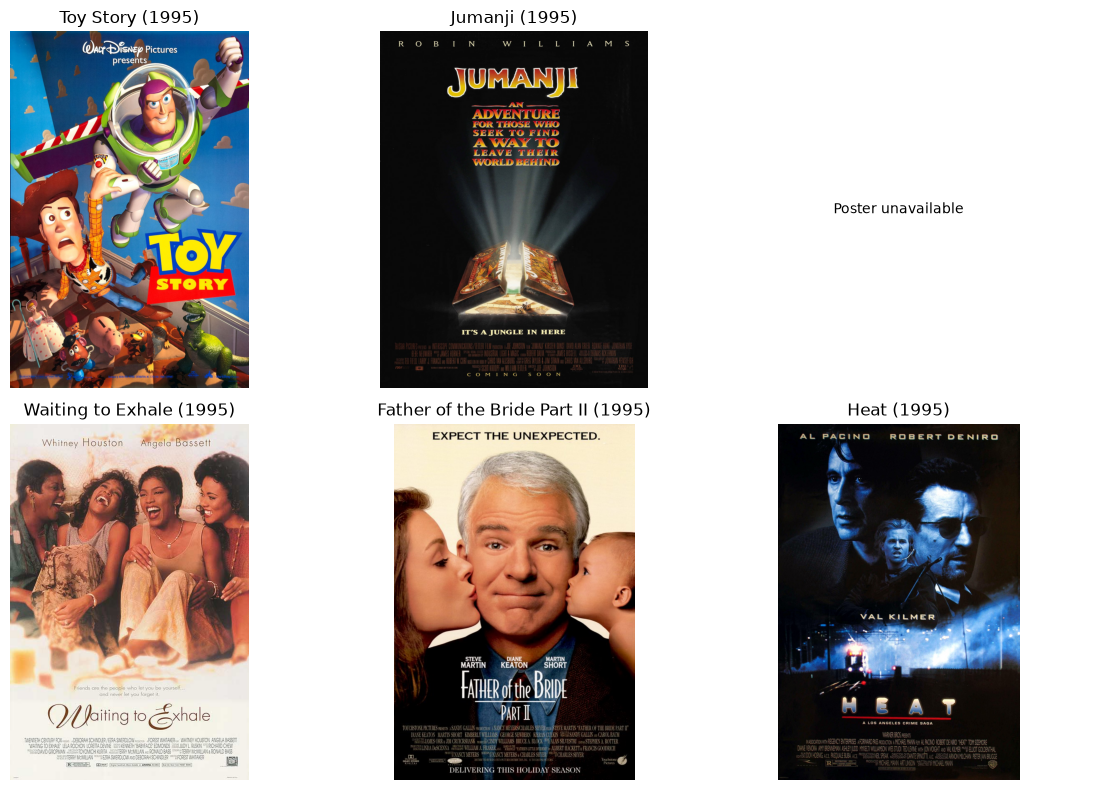

In [37]:
#  Download and preview a few movie posters.

import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

sample_posters = movie_posters.head(6)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, (_, movie) in zip(axes, sample_posters.iterrows()):
    try:
        response = requests.get(
            movie["poster_url"],
            timeout=15,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        ax.imshow(image)
        ax.set_title(movie["title"][:35])
    except Exception as e:
        ax.text(0.5, 0.5, "Poster unavailable",
                ha="center", va="center")
        print("Failed:", movie["title"], "-", str(e)[:100])

    ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:


# Extract visual features from available movie posters.

from io import BytesIO
from PIL import Image
import requests
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

MAX_POSTERS = 200

poster_sample = movie_posters.head(MAX_POSTERS).copy()

visual_features = {}
failed_movies = []

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0"})

for _, movie in tqdm(
    poster_sample.iterrows(),
    total=len(poster_sample),
    desc="Extracting poster features"
):
    movie_id = int(movie["movieId"])

    try:
        response = session.get(
            movie["poster_url"],
            timeout=10
        )
        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        image_tensor = preprocess(image).unsqueeze(0).to(device)

        with torch.no_grad():
            features = image_model(image_tensor)

        visual_features[movie_id] = (
            features.squeeze(0).cpu().numpy()
        )

    except Exception:
        failed_movies.append(movie_id)

print("Posters attempted:", len(poster_sample))
print("Successful feature extractions:", len(visual_features))
print("Failed posters:", len(failed_movies))

if visual_features:
    print(
        "Feature vector shape:",
        next(iter(visual_features.values())).shape
    )

Extracting poster features:   0%|          | 0/200 [00:00<?, ?it/s]

Posters attempted: 200
Successful feature extractions: 187
Failed posters: 13
Feature vector shape: (512,)


In [39]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
#Combine text and visual similarities.

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

ALPHA = 0.7  # 70% text, 30% visual when poster features are available.

# Normalize visual feature vectors for cosine similarity.
visual_movie_ids = list(visual_features.keys())

visual_matrix = np.vstack([
    visual_features[movie_id]
    for movie_id in visual_movie_ids
])

visual_matrix = normalize(visual_matrix)

visual_index = {
    movie_id: idx
    for idx, movie_id in enumerate(visual_movie_ids)
}

print("Movies with visual features:", len(visual_index))
print("Visual feature matrix:", visual_matrix.shape)
print("Text-visual fusion weight:", ALPHA)

Movies with visual features: 187
Visual feature matrix: (187, 512)
Text-visual fusion weight: 0.7


In [41]:
# Generate multimodal recommendations for a user.

def multimodal_recommend(user_id, k=10, alpha=ALPHA):
    user_profile = get_temporal_user_profile(
        user_id,
        lambda_decay=BEST_LAMBDA
    )

    if user_profile is None:
        return pd.DataFrame()

    # Text similarity for every movie.
    text_scores = cosine_similarity(
        user_profile, movie_vectors
    ).ravel()

    recommendations = movies.copy()
    recommendations["text_score"] = text_scores

    # Default to text similarity if no poster features exist.
    recommendations["visual_score"] = 0.0
    recommendations["has_visual"] = (
        recommendations["movieId"].isin(visual_index)
    )

    # Build the user's visual profile from positively rated movies
    # that also have extracted poster features.
    history = train_data[
        (train_data["userId"] == user_id) &
        (train_data["rating"] >= 4) &
        (train_data["movieId"].isin(visual_index))
    ].copy()

    if not history.empty:
        history_indices = [
            visual_index[mid]
            for mid in history["movieId"]
        ]

        weights = np.exp(
            -BEST_LAMBDA * history["age_days"].to_numpy()
        )

        weighted_profile = np.average(
            visual_matrix[history_indices],
            axis=0,
            weights=weights
        )

        visual_scores = cosine_similarity(
            weighted_profile.reshape(1, -1),
            visual_matrix
        ).ravel()

        visual_score_map = {
            mid: visual_scores[idx]
            for mid, idx in visual_index.items()
        }

        recommendations["visual_score"] = (
            recommendations["movieId"]
            .map(visual_score_map)
            .fillna(0.0)
        )

        # Use both modalities only where a candidate poster exists.
        recommendations["score"] = recommendations["text_score"]
        mask = recommendations["has_visual"]

        recommendations.loc[mask, "score"] = (
            alpha * recommendations.loc[mask, "text_score"]
            + (1 - alpha) * recommendations.loc[mask, "visual_score"]
        )

    else:
        recommendations["score"] = recommendations["text_score"]

    # Exclude movies already seen in the training history.
    watched = set(
        train_data.loc[
            train_data["userId"] == user_id, "movieId"
        ]
    )

    recommendations = recommendations[
        ~recommendations["movieId"].isin(watched)
    ].sort_values("score", ascending=False)

    return recommendations.head(k)[
        ["movieId", "title", "genres", "text_score",
         "visual_score", "has_visual", "score"]
    ]

In [42]:
#  Inspect multimodal recommendations for one user.

example_user = int(test_data["userId"].iloc[0])

display(
    multimodal_recommend(example_user, k=10)
)

,movieId,title,genres,text_score,visual_score,has_visual,score
47,48,Pocahontas (1995),Animation|Children's|Musical|Romance,0.440455,0.713184,True,0.522274
12,13,Balto (1995),Animation|Children's,0.345130,0.734542,True,0.461954
1642,1688,Anastasia (1997),Animation|Children's|Musical,0.446811,0.000000,False,0.446811
3090,3159,Fantasia 2000 (1999),Animation|Children's|Musical,0.445929,0.000000,False,0.445929
2490,2559,"King and I, The (1999)",Animation|Children's,0.424377,0.000000,False,0.424377
2012,2081,"Little Mermaid, The (1989)",Animation|Children's|Comedy|Musical|Romance,0.414608,0.000000,False,0.414608
626,631,All Dogs Go to Heaven 2 (1996),Animation|Children's|Musical,0.413745,0.000000,False,0.413745
1262,1282,Fantasia (1940),Animation|Children's|Musical,0.401165,0.000000,False,0.401165
33,34,Babe (1995),Children's|Comedy|Drama,0.273307,0.678252,True,0.394790
105,107,Muppet Treasure Island (1996),Adventure|Children's|Comedy|Musical,0.262268,0.703277,True,0.394570


In [43]:
#  Evaluate multimodal recommendations using Recall@10.

def evaluate_multimodal(k=10, alpha=ALPHA):
    hits = 0
    total_users = 0
    poster_hits = 0
    recommended_items = 0
    poster_recommended_items = 0

    for user_id in test_data["userId"].unique():
        user_test = test_data[test_data["userId"] == user_id]

        test_movie = int(user_test.iloc[0]["movieId"])
        test_rating = user_test.iloc[0]["rating"]

        # Evaluate only users with a positive held-out interaction.
        if test_rating < 4:
            continue

        recommendations = multimodal_recommend(
            user_id, k=k, alpha=alpha
        )

        recommended_ids = set(recommendations["movieId"])

        if test_movie in recommended_ids:
            hits += 1

            if test_movie in visual_index:
                poster_hits += 1

        total_users += 1
        recommended_items += len(recommendations)
        poster_recommended_items += int(
            recommendations["has_visual"].sum()
        )

    recall = hits / total_users if total_users else 0.0
    poster_coverage = (
        poster_recommended_items / recommended_items
        if recommended_items else 0.0
    )

    return {
        "Recall@10": recall,
        "Evaluated users": total_users,
        "Poster coverage in recommendations": poster_coverage,
        "Hits on movies with visual features": poster_hits
    }


multimodal_results = evaluate_multimodal(k=10)

print("Multimodal evaluation results:")
for metric, value in multimodal_results.items():
    if isinstance(value, float):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Multimodal evaluation results:
Recall@10: 0.0194
Evaluated users: 3563
Poster coverage in recommendations: 0.5283
Hits on movies with visual features: 19


In [44]:
# Cell 44: Compare all recommendation models.

comparison = pd.DataFrame([
    {
        "Model": "Popularity",
        "Recall@10": 0.020760914875105248
    },
    {
        "Model": "Content-Based",
        "Recall@10": 0.021333039601459445
    },
    {
        "Model": "Temporal Content-Based",
        "Recall@10": BEST_TEMPORAL_RECALL
    },
    {
        "Model": "Temporal Multimodal",
        "Recall@10": multimodal_results["Recall@10"]
    }
])

comparison = comparison.sort_values(
    "Recall@10",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Model,Recall@10
0,Temporal Content-Based,0.024137
1,Content-Based,0.021333
2,Popularity,0.020761
3,Temporal Multimodal,0.019366


In [45]:
# Cell 45: Inspect visual feature coverage.

total_movies = movies["movieId"].nunique()
movies_with_visuals = len(visual_index)

print("Total movies:", total_movies)
print("Movies with extracted visual features:", movies_with_visuals)
print(
    "Visual feature coverage: "
    f"{100 * movies_with_visuals / total_movies:.2f}%"
)

print(
    "Fraction of recommendations with posters:",
    f"{multimodal_results['Poster coverage in recommendations']:.2%}"
)

Total movies: 3883
Movies with extracted visual features: 187
Visual feature coverage: 4.82%
Fraction of recommendations with posters: 52.83%


In [46]:
#Compare different multimodal fusion weights.

alpha_values = [0.7, 0.8, 0.9, 1.0]
fusion_results = []

for alpha in alpha_values:
    result = evaluate_multimodal(k=10, alpha=alpha)

    fusion_results.append({
        "Text weight (alpha)": alpha,
        "Visual weight": 1 - alpha,
        "Recall@10": result["Recall@10"],
        "Poster coverage": result[
            "Poster coverage in recommendations"
        ]
    })

fusion_results_df = pd.DataFrame(fusion_results)
display(fusion_results_df)

,Text weight (alpha),Visual weight,Recall@10,Poster coverage
0,0.7,0.3,0.019366,0.528291
1,0.8,0.2,0.021892,0.301824
2,0.9,0.1,0.023014,0.104070
3,1.0,0.0,0.024137,0.028010


In [47]:
# Cell 47: Build the user's temporal preference profile.

import pandas as pd
import numpy as np
import json

def build_reasoning_context(user_id, k=5):
    # Get positively rated training interactions.
    history = train_data[
        (train_data["userId"] == user_id) &
        (train_data["rating"] >= 4)
    ].copy()

    # Add movie titles and genres explicitly.
    history = history.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left",
        suffixes=("", "_movie")
    )

    # Calculate how old each interaction is.
    latest_timestamp = history["timestamp"].max()

    history["age_days"] = (
        latest_timestamp - history["timestamp"]
    ) / 86400

    # Show the five most recent liked movies.
    recent_likes = history.sort_values(
        "timestamp", ascending=False
    ).head(5)

    recent_likes = recent_likes[
        ["title", "genres", "rating", "age_days"]
    ].to_dict("records")

    # Generate recommendations using the existing model.
    recommendations = multimodal_recommend(
        user_id, k=k, alpha=ALPHA
    )

    return {
        "user_id": int(user_id),
        "recent_likes": recent_likes,
        "recommendations": recommendations[
            [
                "movieId", "title", "genres",
                "text_score", "visual_score",
                "has_visual", "score"
            ]
        ].to_dict("records")
    }


example_user = int(test_data["userId"].iloc[0])

reasoning_context = build_reasoning_context(
    example_user,
    k=5
)

print("Recent user preferences:")
display(pd.DataFrame(reasoning_context["recent_likes"]))

print("Candidate recommendations:")
display(pd.DataFrame(reasoning_context["recommendations"]))

Recent user preferences:


,title,genres,rating,age_days
0,Mulan (1998),Animation|Children's,4,0.000000
1,Hercules (1997),Adventure|Animation|Children's|Comedy|Musical,4,0.000000
2,"Hunchback of Notre Dame, The (1996)",Animation|Children's|Musical,4,0.000451
3,"Bug's Life, A (1998)",Animation|Children's|Comedy,5,0.000451
4,Antz (1998),Animation|Children's,4,0.000451


Candidate recommendations:


,movieId,title,genres,text_score,visual_score,has_visual,score
0,48,Pocahontas (1995),Animation|Children's|Musical|Romance,0.440455,0.713184,True,0.522274
1,13,Balto (1995),Animation|Children's,0.345130,0.734542,True,0.461954
2,1688,Anastasia (1997),Animation|Children's|Musical,0.446811,0.000000,False,0.446811
3,3159,Fantasia 2000 (1999),Animation|Children's|Musical,0.445929,0.000000,False,0.445929
4,2559,"King and I, The (1999)",Animation|Children's,0.424377,0.000000,False,0.424377


In [48]:
# Cell 48: Create an evidence-grounded LLM prompt.

import json

def create_reasoning_prompt(context):
    user_data = json.dumps(
        context,
        indent=2,
        ensure_ascii=False
    )

    prompt = f"""
You are a movie recommendation explanation assistant.

Use only the evidence provided below.

RECOMMENDATION DATA:
{user_data}

For each recommended movie:
1. State its title and genres.
2. Explain why it may match the user's preferences.
3. Identify relevant previously liked movies or genre patterns.
4. Explain whether text similarity, poster similarity, or both
   contributed to the recommendation.
5. Keep the explanation concise and understandable.

RULES:
- Do not invent plots, actors, scenes, or user preferences.
- If has_visual is false, do not claim poster similarity
  contributed to that movie's score.
- Similarity scores are not probabilities.
- Present explanations as plausible matches, not certainties.
- Use only the supplied evidence.

Return valid JSON in this format:
{{
  "recommendations": [
    {{
      "title": "Movie title",
      "genres": "Movie genres",
      "reason": "Evidence-based explanation",
      "evidence": ["Supporting preference"],
      "modalities": ["text", "poster"]
    }}
  ]
}}

Include only modalities that actually contributed to the score.
Return JSON only.
"""
    return prompt


reasoning_prompt = create_reasoning_prompt(reasoning_context)

print(reasoning_prompt)


You are a movie recommendation explanation assistant.

Use only the evidence provided below.

RECOMMENDATION DATA:
{
  "user_id": 1,
  "recent_likes": [
    {
      "title": "Mulan (1998)",
      "genres": "Animation|Children's",
      "rating": 4,
      "age_days": 0.0
    },
    {
      "title": "Hercules (1997)",
      "genres": "Adventure|Animation|Children's|Comedy|Musical",
      "rating": 4,
      "age_days": 0.0
    },
    {
      "title": "Hunchback of Notre Dame, The (1996)",
      "genres": "Animation|Children's|Musical",
      "rating": 4,
      "age_days": 0.00045138888888888887
    },
    {
      "title": "Bug's Life, A (1998)",
      "genres": "Animation|Children's|Comedy",
      "rating": 5,
      "age_days": 0.00045138888888888887
    },
    {
      "title": "Antz (1998)",
      "genres": "Animation|Children's",
      "rating": 4,
      "age_days": 0.00045138888888888887
    }
  ],
  "recommendations": [
    {
      "movieId": 48,
      "title": "Pocahontas (1995)",
 

In [49]:
%pip install -U google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
# Cell 50: Generate LLM explanations.

import os
from getpass import getpass
from google import genai

api_key = os.environ.get("GEMINI_API_KEY")

if not api_key:
    api_key = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=api_key)

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=reasoning_prompt
)

llm_output = response.text

print(llm_output)

```json
{
  "recommendations": [
    {
      "title": "Pocahontas (1995)",
      "genres": "Animation|Children's|Musical|Romance",
      "reason": "This movie aligns with your preference for 'Animation', 'Children's', and 'Musical' genres, similar to your recently liked movies 'Hercules' and 'The Hunchback of Notre Dame'.",
      "evidence": [
        "Animation",
        "Children's",
        "Musical",
        "Hercules (1997)",
        "Hunchback of Notre Dame, The (1996)"
      ],
      "modalities": [
        "text",
        "poster"
      ]
    },
    {
      "title": "Balto (1995)",
      "genres": "Animation|Children's",
      "reason": "It matches the 'Animation' and 'Children's' genres consistently present in all your recently liked movies, including 'Mulan' and 'Antz'.",
      "evidence": [
        "Animation",
        "Children's",
        "Mulan (1998)",
        "Antz (1998)"
      ],
      "modalities": [
        "text",
        "poster"
      ]
    },
    {
      "title"

In [51]:
# Cell 51: Parse and display the generated explanations.

import json
import pandas as pd

def parse_llm_output(output):
    output = output.strip()

    if output.startswith("```"):
        lines = output.splitlines()
        output = "\n".join(
            line for line in lines
            if not line.strip().startswith("```")
        )

    result = json.loads(output)

    return pd.DataFrame(result["recommendations"])


try:
    explanation_df = parse_llm_output(llm_output)
    display(explanation_df)

except (json.JSONDecodeError, KeyError, TypeError) as error:
    print("Could not parse the response as JSON:", error)
    print("Raw response:")
    print(llm_output)

,title,genres,reason,evidence,modalities
0,Pocahontas (1995),Animation|Children's|Musical|Romance,This movie aligns with your preference for 'An...,"[Animation, Children's, Musical, Hercules (199...","[text, poster]"
1,Balto (1995),Animation|Children's,It matches the 'Animation' and 'Children's' ge...,"[Animation, Children's, Mulan (1998), Antz (19...","[text, poster]"
2,Anastasia (1997),Animation|Children's|Musical,"This movie shares the 'Animation', 'Children's...","[Animation, Children's, Musical, Hercules (199...",[text]
3,Fantasia 2000 (1999),Animation|Children's|Musical,It aligns with your preference for 'Animation'...,"[Animation, Children's, Musical, Hercules (199...",[text]
4,"King and I, The (1999)",Animation|Children's,This movie matches the 'Animation' and 'Childr...,"[Animation, Children's, Mulan (1998), Antz (19...",[text]


In [52]:
#  Save recommendation and explanation results.

import os

output_dir = "results"
os.makedirs(output_dir, exist_ok=True)

# Save model comparison.
comparison.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

# Save fusion-weight experiments if available.
if "fusion_results_df" in globals():
    fusion_results_df.to_csv(
        os.path.join(output_dir, "fusion_experiments.csv"),
        index=False
    )

# Save multimodal recommendations.
recommendations_df = pd.DataFrame(
    reasoning_context["recommendations"]
)

recommendations_df.to_csv(
    os.path.join(output_dir, "multimodal_recommendations.csv"),
    index=False
)

# Save LLM explanations.
explanation_df.to_csv(
    os.path.join(output_dir, "llm_explanations.csv"),
    index=False
)

print("Research outputs saved in:", output_dir)
print(os.listdir(output_dir))

Research outputs saved in: results
['fusion_experiments.csv', 'llm_explanations.csv', 'model_comparison.csv', 'multimodal_recommendations.csv']


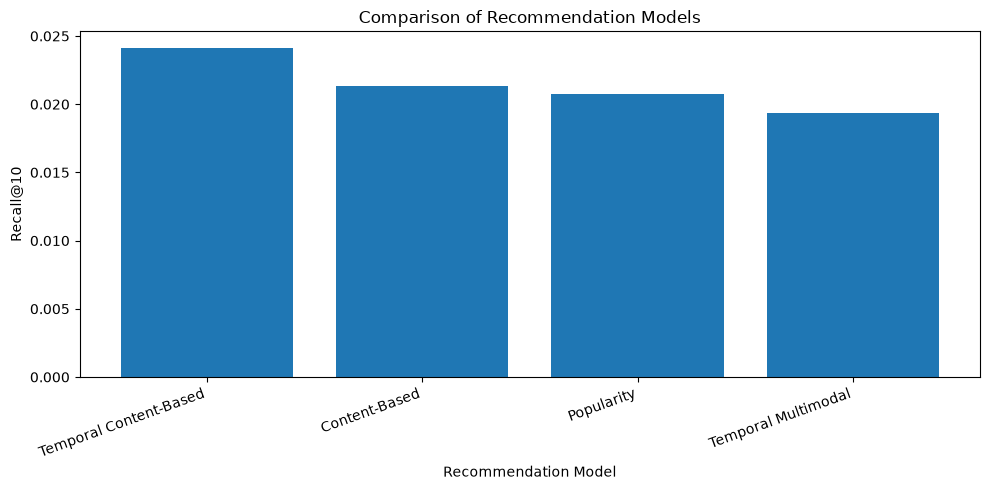

In [53]:
#Plot Recall@10 for all recommendation models.

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Model"],
    comparison["Recall@10"]
)

plt.ylabel("Recall@10")
plt.xlabel("Recommendation Model")
plt.title("Comparison of Recommendation Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [54]:
# Summarize the best-performing model.

best_model = comparison.loc[
    comparison["Recall@10"].idxmax()
]

print("FINAL EXPERIMENT SUMMARY")
print("-" * 40)
print("Number of movies:", movies["movieId"].nunique())
print("Number of users:", ratings["userId"].nunique())
print("Movies with visual features:", len(visual_index))
print("Best tested temporal decay:", BEST_LAMBDA)
print("Best-performing model:", best_model["Model"])
print(f"Best Recall@10: {best_model['Recall@10']:.6f}")
print("LLM explanations generated:", len(explanation_df))

FINAL EXPERIMENT SUMMARY
----------------------------------------
Number of movies: 3883
Number of users: 6040
Movies with visual features: 187
Best tested temporal decay: 0.01
Best-performing model: Temporal Content-Based
Best Recall@10: 0.024137
LLM explanations generated: 5


In [55]:
# Cell 56: Interactive movie recommendation

user_id = int(input("Enter MovieLens User ID: "))

if user_id not in train_data["userId"].values:
    print("User ID not found in the training dataset.")

else:
    print(f"\nRecommendations for User {user_id}:\n")

    user_recommendations = multimodal_recommend(
        user_id,
        k=5,
        alpha=ALPHA
    )

    display(user_recommendations)


Recommendations for User 1:



,movieId,title,genres,text_score,visual_score,has_visual,score
47,48,Pocahontas (1995),Animation|Children's|Musical|Romance,0.440455,0.713184,True,0.522274
12,13,Balto (1995),Animation|Children's,0.345130,0.734542,True,0.461954
1642,1688,Anastasia (1997),Animation|Children's|Musical,0.446811,0.000000,False,0.446811
3090,3159,Fantasia 2000 (1999),Animation|Children's|Musical,0.445929,0.000000,False,0.445929
2490,2559,"King and I, The (1999)",Animation|Children's,0.424377,0.000000,False,0.424377


In [57]:
# Generate and display Gemini explanations

reasoning_context = build_reasoning_context(user_id, k=5)
reasoning_prompt = create_reasoning_prompt(reasoning_context)

print("\nGenerating explanations using Gemini...\n")

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=reasoning_prompt
)

llm_output = response.text

print("=" * 65)
print("          GEMINI-POWERED RECOMMENDATION EXPLANATIONS")
print("=" * 65)

try:
    explanation_df = parse_llm_output(llm_output)

    for rank, (_, item) in enumerate(
        explanation_df.iterrows(), start=1
    ):
        print(f"\n{rank}. {item['title']}")
        print("-" * 50)
        print(f"Genres       : {item['genres']}")
        print(f"Explanation  : {item['reason']}")

        if item.get("evidence"):
            print(f"Evidence     : {item['evidence']}")

        if item.get("modalities"):
            print(f"Modalities   : {item['modalities']}")

except (ValueError, KeyError, TypeError) as error:
    print("Could not format the response:", error)
    print("\nRaw Gemini response:\n")
    print(llm_output)

print("\n" + "=" * 65)
print("             END OF RECOMMENDATION REPORT")
print("=" * 65)


Generating explanations using Gemini...

          GEMINI-POWERED RECOMMENDATION EXPLANATIONS

1. Pocahontas (1995)
--------------------------------------------------
Genres       : Animation|Children's|Musical|Romance
Explanation  : This film aligns with your preference for 'Animation' and 'Children's' genres, a consistent theme across your recent likes. It also matches your interest in 'Musical' films, similar to 'Hercules (1997)' and 'The Hunchback of Notre Dame (1996)'.
Evidence     : ['Mulan (1998)', 'Hercules (1997)', 'Hunchback of Notre Dame, The (1996)', "Bug's Life, A (1998)", 'Antz (1998)']
Modalities   : ['text', 'poster']

2. Balto (1995)
--------------------------------------------------
Genres       : Animation|Children's
Explanation  : This movie fits your strong preference for 'Animation' and 'Children's' genres, which is evident in all your recently liked movies.
Evidence     : ['Mulan (1998)', 'Hercules (1997)', 'Hunchback of Notre Dame, The (1996)', "Bug's Life, A (